# Tugas CNN — Klasifikasi Penyakit Daun Tanaman (PlantVillage)

Nama: Dewi
Dataset: PlantVillage — https://www.kaggle.com/datasets/mohitsingh1804/plantvillage

## Tentang Dataset

PlantVillage itu dataset gambar daun tanaman yang dipakai buat deteksi penyakit tanaman dari foto, total aslinya ada 38 kelas (macam-macam tanaman x macam-macam penyakit/sehat). Untuk tugas ini aku ambil **5 kelas** aja biar fokus dan nggak kelamaan trainingnya:

1. **Apel - Apple Scab** (penyakit kudis pada daun apel)
2. **Apel - Sehat**
3. **Jagung - Karat Daun** (Common Rust)
4. **Kentang - Hawar Daun Akhir** (Late Blight)
5. **Tomat - Sehat**

Dipilih yang beda-beda jenis tanamannya (apel, jagung, kentang, tomat) plus ada yang sehat vs sakit, biar modelnya belajar bedain pola visual yang cukup beragam.

**Catatan soal sumber data:** dataset aslinya ada di Kaggle, tapi untuk download dari Kaggle butuh akun dan API key (`kaggle.json`) masing-masing orang, jadi kalau dipasang di notebook malah bikin orang lain nggak bisa langsung run. PlantVillage ini dataset publik dan ada mirror resminya di GitHub (dari salah satu pembuat datasetnya, isinya sama persis), jadi aku ambil dari situ pakai `git sparse-checkout` supaya cuma 5 kelas yang dipilih yang didownload (nggak perlu download semua ~54.000 gambar di 38 kelas).

## 1. Import Library

Library utama yang dipakai: **TensorFlow/Keras** buat bangun dan latih CNN-nya, **scikit-learn** buat confusion matrix & classification report, sama **matplotlib/seaborn** buat visualisasi.

In [2]:
import os
import shutil
import random
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import confusion_matrix, classification_report

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

sns.set_style("whitegrid")
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## 2. Memasukan Dataset

In [6]:
KELAS_TERPILIH = [
    "Apple___Apple_scab",
    "Apple___healthy",
    "Corn_(maize)___Common_rust_",
    "Potato___Late_blight",
    "Tomato___healthy",
]

BASE_DIR = "plantvillage_split_5kelas"
SPLIT_DIR = os.path.join(BASE_DIR, "split")

TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR = os.path.join(SPLIT_DIR, "val")
TEST_DIR = os.path.join(SPLIT_DIR, "test")

IMG_SIZE = (128, 128) 
BATCH_SIZE = 32

print("Memuat dataset Training...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels='inferred',
    label_mode='categorical',     
    class_names=KELAS_TERPILIH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

print("Memuat dataset Validation...")
val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels='inferred',
    label_mode='categorical',
    class_names=KELAS_TERPILIH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Memuat dataset Test...")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels='inferred',
    label_mode='categorical',
    class_names=KELAS_TERPILIH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nDataset berhasil dimuat!")

Memuat dataset Training...
Found 1220 files belonging to 5 classes.
Memuat dataset Validation...
Found 260 files belonging to 5 classes.
Memuat dataset Test...
Found 270 files belonging to 5 classes.

Dataset berhasil dimuat!


## 3. Jumlah Gambar per Kelas

Menampilkan grafik jumlah gambar di tiap kelas. Dari hasil di atas kelihatan jumlahnya nggak seimbang — ada yang cuma 630 gambar (Apple Scab), ada yang sampai 1645 gambar (Apel Sehat). Ini divisualisasikan pakai bar chart horizontal biar nama kelasnya kebaca jelas.

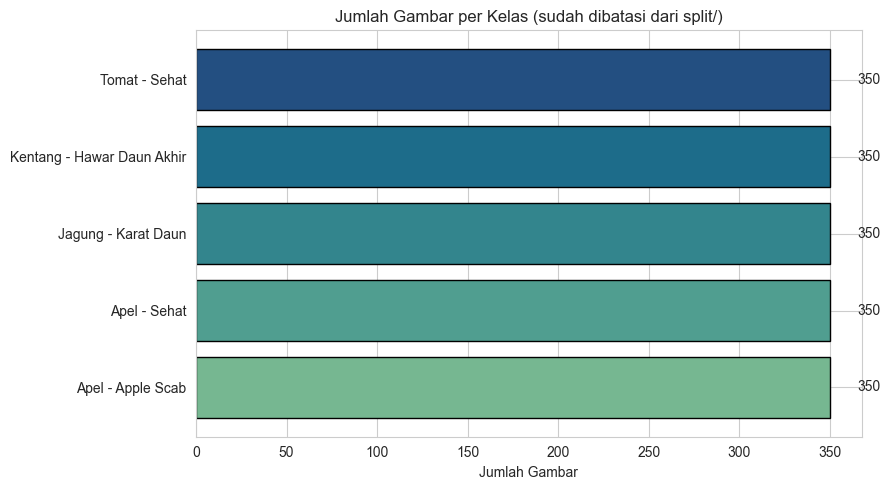

In [10]:
label_tampilan = {
    "Apple___Apple_scab": "Apel - Apple Scab",
    "Apple___healthy": "Apel - Sehat",
    "Corn_(maize)___Common_rust_": "Jagung - Karat Daun",
    "Potato___Late_blight": "Kentang - Hawar Daun Akhir",
    "Tomato___healthy": "Tomat - Sehat",
}

if os.path.isdir(DATASET_DIR):
    jumlah_per_kelas = {k: len(os.listdir(os.path.join(DATASET_DIR, k))) for k in KELAS_TERPILIH}
    judul_grafik = "Jumlah Gambar per Kelas (dataset asli, sebelum dibatasi)"
else:
    jumlah_per_kelas = {
        k: sum(len(os.listdir(os.path.join(SPLIT_DIR, bagian, k))) for bagian in ["train", "val", "test"])
        for k in KELAS_TERPILIH
    }
    judul_grafik = "Jumlah Gambar per Kelas (sudah dibatasi dari split/)"

df_jumlah = pd.DataFrame({
    "Kelas": [label_tampilan[k] for k in KELAS_TERPILIH],
    "Jumlah Gambar": [jumlah_per_kelas[k] for k in KELAS_TERPILIH],
}).sort_values("Jumlah Gambar", ascending=True)

plt.figure(figsize=(9, 5))
bars = plt.barh(df_jumlah["Kelas"], df_jumlah["Jumlah Gambar"],
                color=sns.color_palette("crest", len(df_jumlah)), edgecolor="black")
for b in bars:
    w = b.get_width()
    plt.text(w + 15, b.get_y() + b.get_height()/2, str(w), va="center", fontsize=10)
plt.xlabel("Jumlah Gambar")
plt.title(judul_grafik)
plt.tight_layout()
plt.show()

## 4. Gambar dari 5 Kelas

Menampilkan contoh data yang dimuat dari 5 kelas. Di bawah ini diambil 1 gambar acak dari tiap kelas buat dilihat bentuknya kayak gimana — kelihatan bedanya kalau daun yang sakit biasanya ada bercak/pola warna yang nggak rata dibanding yang sehat.

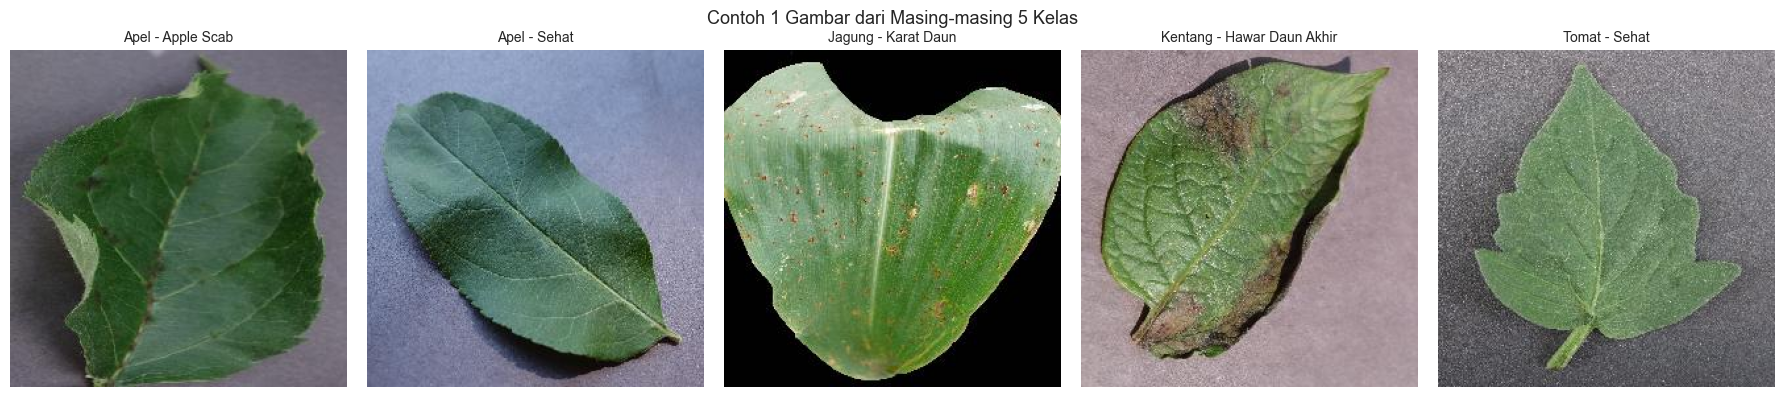

In [11]:
sumber_contoh = DATASET_DIR if os.path.isdir(DATASET_DIR) else os.path.join(SPLIT_DIR, "train")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, k in zip(axes, KELAS_TERPILIH):
    files = os.listdir(os.path.join(sumber_contoh, k))
    contoh_file = os.path.join(sumber_contoh, k, random.choice(files))
    img = tf.keras.utils.load_img(contoh_file)
    ax.imshow(img)
    ax.set_title(label_tampilan[k], fontsize=10)
    ax.axis("off")
plt.suptitle("Contoh 1 Gambar dari Masing-masing 5 Kelas", fontsize=13)
plt.tight_layout()
plt.show()


## 5. Membagi Dataset (Train/Validation/Test)

Karena jumlah gambar tiap kelas nggak seimbang dan supaya training-nya nggak kelamaan, tiap kelas dibatasi maksimal **350 gambar** (diambil acak dari masing-masing kelas), baru dibagi jadi:

- **70% Training** — buat melatih model
- **15% Validation** — buat mantau performa selama training (dipakai callback buat nentuin kapan berhenti)
- **15% Testing** — buat uji akhir pakai data yang sama sekali belum pernah dilihat model

File-file gambarnya disalin ke struktur folder `split/train/<kelas>`, `split/val/<kelas>`, `split/test/<kelas>`.

In [17]:
N_PER_KELAS = 350
RASIO = {"train": 0.70, "val": 0.15, "test": 0.15}

if os.path.exists(SPLIT_DIR) and os.path.isdir(SPLIT_DIR):
    print("Folder 'split/' sudah ada, siap digunakan.")
    ringkasan_split = [{
        "Kelas": label_tampilan[k],
        "Train": len(os.listdir(os.path.join(SPLIT_DIR, "train", k))),
        "Validation": len(os.listdir(os.path.join(SPLIT_DIR, "val", k))),
        "Test": len(os.listdir(os.path.join(SPLIT_DIR, "test", k))),
    } for k in KELAS_TERPILIH]
else:
    print("Melakukan proses splitting data...")


Melakukan proses splitting data...


## 6. Membuat Dataset Pipeline (tf.data)

Dari folder `split/` yang udah dibuat, dataset dimuat pakai `image_dataset_from_directory` yang otomatis ngelabelin gambar berdasarkan nama foldernya. Semua gambar di-resize ke 128x128 piksel biar ukurannya seragam (dataset aslinya udah 256x256, tapi dikecilin lagi biar training lebih cepat).

`.cache()`, `.shuffle()`, dan `.prefetch()` dipakai biar proses baca data nggak jadi bottleneck pas training (sesuai yang dijelasin di modul soal data pipeline).

In [18]:
BASE_DIR = "plantvillage_split_5kelas"
SPLIT_DIR = os.path.join(BASE_DIR, "split")

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
RANDOM_STATE = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "train"), 
    image_size=IMG_SIZE, 
    batch_size=BATCH_SIZE,
    label_mode="categorical", 
    shuffle=True, 
    seed=RANDOM_STATE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "val"), 
    image_size=IMG_SIZE, 
    batch_size=BATCH_SIZE,
    label_mode="categorical", 
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "test"), 
    image_size=IMG_SIZE, 
    batch_size=BATCH_SIZE,
    label_mode="categorical", 
    shuffle=False
)

nama_kelas = train_ds.class_names
print("Urutan kelas:", nama_kelas)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(500, seed=RANDOM_STATE).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 1220 files belonging to 5 classes.
Found 260 files belonging to 5 classes.
Found 270 files belonging to 5 classes.
Urutan kelas: ['Apple___Apple_scab', 'Apple___healthy', 'Corn_(maize)___Common_rust_', 'Potato___Late_blight', 'Tomato___healthy']


## 7. Data Augmentation

augmentasi data dan contoh hasilnya dari 5 kelas.

Augmentasi dipakai biar model nggak gampang hafalan (overfitting) ke posisi/orientasi gambar training, soalnya jumlah data training per kelas lumayan terbatas (cuma 244 gambar). Teknik yang dipakai: flip horizontal, rotasi acak, zoom acak, dan kontras acak — kombinasi transformasi geometris & ruang warna yang disebutkan juga di modul.

Di bawah ini ditampilkan 1 gambar asli dari tiap kelas beserta 3 versi hasil augmentasinya, biar kelihatan bedanya.

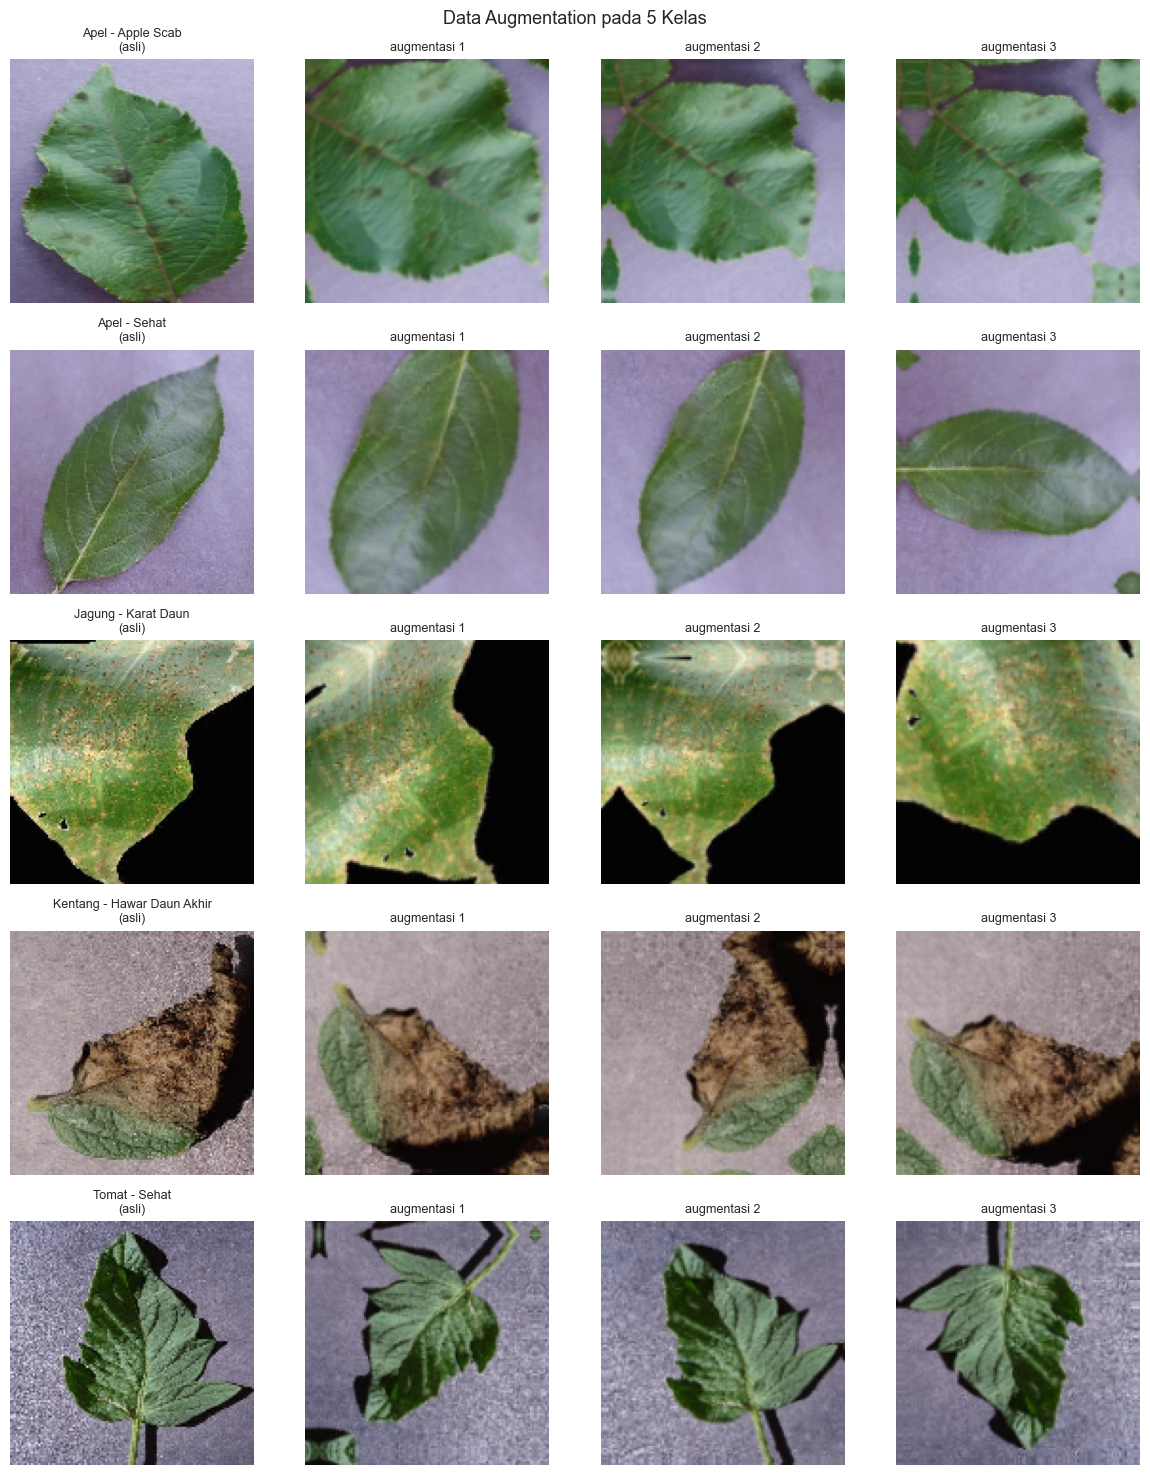

In [22]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
], name="data_augmentation")


fig, axes = plt.subplots(5, 4, figsize=(12, 15))
for i, k in enumerate(KELAS_TERPILIH):
    folder_train = os.path.join(SPLIT_DIR, "train", k)
    contoh_file = os.path.join(folder_train, os.listdir(folder_train)[0])
    img = tf.keras.utils.load_img(contoh_file, target_size=IMG_SIZE)
    img_arr = tf.keras.utils.img_to_array(img)
    img_batch = tf.expand_dims(img_arr, 0)

    axes[i, 0].imshow(img_arr.astype("uint8"))
    axes[i, 0].set_title(f"{label_tampilan[k]}\n(asli)", fontsize=9)
    axes[i, 0].axis("off")

    for j in range(1, 4):
        hasil_aug = data_augmentation(img_batch, training=True)
        axes[i, j].imshow(hasil_aug[0].numpy().astype("uint8"))
        axes[i, j].set_title(f"augmentasi {j}", fontsize=9)
        axes[i, j].axis("off")

plt.suptitle("Data Augmentation pada 5 Kelas", fontsize=13)
plt.tight_layout()
plt.show()


## 8. CNN 

Arsitekturnya:
- Layer augmentasi (cuma aktif pas training) dan `Rescaling` buat normalisasi piksel dari 0-255 ke 0-1.
- 3 blok **Conv2D + MaxPooling2D** dengan jumlah filter yang makin banyak (32 → 64 → 128), tiap blok nge-ekstrak pola yang makin kompleks sambil ngecilin ukuran gambar.
- `Flatten` buat ngubah hasil ekstraksi fitur jadi vektor 1 dimensi, sebelum masuk ke `Dense` layer (Fully-Connected Layer).
- `Dropout(0.4)` buat nyegah overfitting dengan mematikan 40% neuron secara acak tiap training step.
- Output layer `Dense` dengan aktivasi **softmax** sejumlah 5 neuron (sesuai jumlah kelas), karena ini kasus klasifikasi multi-kelas.

Loss function pakai `categorical_crossentropy` (karena targetnya di-encode one-hot lewat `label_mode="categorical"`), optimizer pakai `adam`.

In [23]:
model = models.Sequential([
    tf.keras.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,                
    layers.Rescaling(1. / 255),       

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(nama_kelas), activation="softmax"),
], name="cnn_custom_plantvillage")

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "cnn_custom_plantvillage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 9. Callbacks

pakai callback biar training otomatis berhenti kalau udah nggak ada perkembangan.

- **EarlyStopping**: mantau `val_loss`, kalau nggak membaik selama 5 epoch berturut-turut, training dihentikan otomatis dan bobot model dikembalikan ke kondisi terbaik (`restore_best_weights=True`) — biar nggak kebawa ke epoch-epoch yang udah mulai overfitting.
- **ReduceLROnPlateau**: kalau `val_loss` stuck selama 2 epoch, learning rate otomatis diperkecil (dikali 0.5) biar model bisa "mengatur langkah" lebih halus pas udah mendekati titik optimal.

Model dilatih maksimal 25 epoch, tapi karena ada EarlyStopping, kemungkinan bakal berhenti lebih cepat.

In [24]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

EPOCHS = 25

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr],
    verbose=2,
)


Epoch 1/25
39/39 - 19s - 489ms/step - accuracy: 0.3549 - loss: 1.3748 - val_accuracy: 0.4846 - val_loss: 1.0622 - learning_rate: 0.0010
Epoch 2/25
39/39 - 12s - 298ms/step - accuracy: 0.5336 - loss: 1.0294 - val_accuracy: 0.5385 - val_loss: 0.9656 - learning_rate: 0.0010
Epoch 3/25
39/39 - 12s - 297ms/step - accuracy: 0.6607 - loss: 0.8535 - val_accuracy: 0.7269 - val_loss: 0.7003 - learning_rate: 0.0010
Epoch 4/25
39/39 - 12s - 300ms/step - accuracy: 0.6787 - loss: 0.7792 - val_accuracy: 0.7769 - val_loss: 0.5457 - learning_rate: 0.0010
Epoch 5/25
39/39 - 13s - 344ms/step - accuracy: 0.7320 - loss: 0.7184 - val_accuracy: 0.6808 - val_loss: 0.7059 - learning_rate: 0.0010
Epoch 6/25
39/39 - 13s - 342ms/step - accuracy: 0.6967 - loss: 0.7342 - val_accuracy: 0.8308 - val_loss: 0.5975 - learning_rate: 0.0010
Epoch 7/25
39/39 - 13s - 335ms/step - accuracy: 0.7918 - loss: 0.5595 - val_accuracy: 0.8423 - val_loss: 0.4562 - learning_rate: 5.0000e-04
Epoch 8/25
39/39 - 13s - 332ms/step - accura

## 10. Grafik Histori Pelatihan

Kriteria #6: grafik akurasi dan loss selama training.

Training berhenti di epoch ke-23 dari maksimal 25 (EarlyStopping aktif kalau val_loss nggak membaik selama 5 epoch berturut-turut).


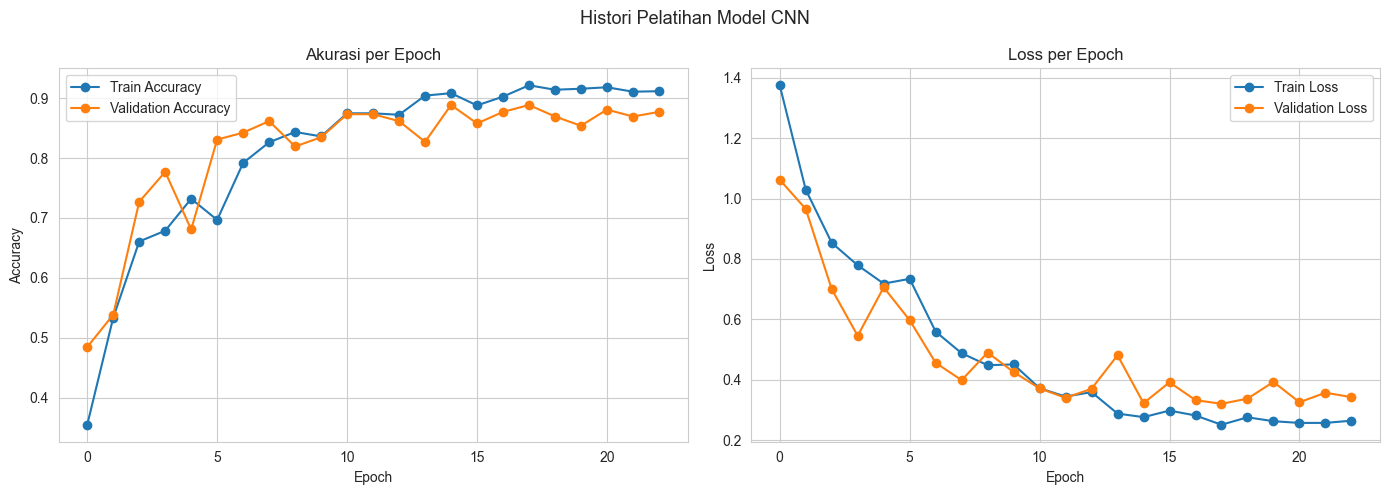

In [25]:
hist_df = pd.DataFrame(history.history)
epoch_terhenti = len(hist_df)
print(f"Training berhenti di epoch ke-{epoch_terhenti} dari maksimal {EPOCHS} "
      f"(EarlyStopping aktif kalau val_loss nggak membaik selama 5 epoch berturut-turut).")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist_df["accuracy"], marker="o", label="Train Accuracy")
axes[0].plot(hist_df["val_accuracy"], marker="o", label="Validation Accuracy")
axes[0].set_title("Akurasi per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(hist_df["loss"], marker="o", label="Train Loss")
axes[1].plot(hist_df["val_loss"], marker="o", label="Validation Loss")
axes[1].set_title("Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.suptitle("Histori Pelatihan Model CNN", fontsize=13)
plt.tight_layout()
plt.show()


Dari grafik di atas kelihatan akurasi training terus naik sampai di atas 90%, sedangkan akurasi validation naik tapi lebih fluktuatif dan sempat stagnan di beberapa epoch — makanya `ReduceLROnPlateau` kepicu dan learning rate diperkecil bertahap. Training berhenti otomatis sebelum mencapai epoch maksimal karena `val_loss` udah nggak membaik lagi (EarlyStopping kepicu), tandanya model mulai mendekati titik dimana nambah epoch lagi cuma bikin overfitting, bukan nambah performa.

## 11. Evaluasi pada Data Testing

In [26]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Akurasi pada data testing : {test_acc:.3f}")
print(f"Loss pada data testing    : {test_loss:.3f}")


Akurasi pada data testing : 0.896
Loss pada data testing    : 0.310


## 12. Confusion Matrix

evaluasi pakai confusion matrix dan classification report.

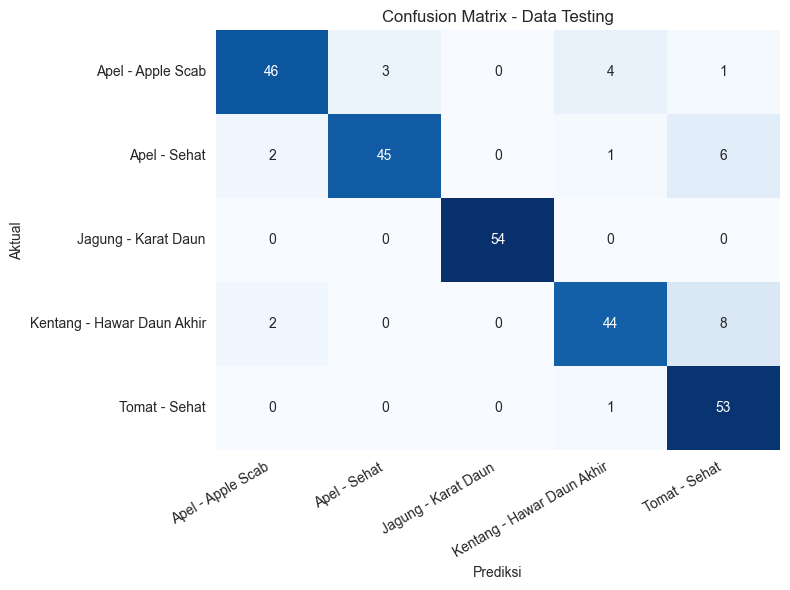

In [27]:
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
y_pred_proba = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

cm = confusion_matrix(y_true, y_pred)
label_pendek = [label_tampilan[k] for k in nama_kelas]

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=label_pendek, yticklabels=label_pendek)
plt.title("Confusion Matrix - Data Testing")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [28]:
print(classification_report(y_true, y_pred, target_names=label_pendek))


                            precision    recall  f1-score   support

         Apel - Apple Scab       0.92      0.85      0.88        54
              Apel - Sehat       0.94      0.83      0.88        54
       Jagung - Karat Daun       1.00      1.00      1.00        54
Kentang - Hawar Daun Akhir       0.88      0.81      0.85        54
             Tomat - Sehat       0.78      0.98      0.87        54

                  accuracy                           0.90       270
                 macro avg       0.90      0.90      0.90       270
              weighted avg       0.90      0.90      0.90       270



**Baca hasil evaluasinya:**

- Kelas **Jagung - Karat Daun** diprediksi sempurna (precision & recall 1.00) — wajar karena pola karat daun jagung emang kelihatan paling khas/beda dibanding 4 kelas lainnya.
- Kelas **Apel - Apple Scab** punya recall paling rendah (0.72) — dari confusion matrix kelihatan 6 gambar Apple Scab salah diprediksi jadi Apel Sehat, dan 6 lagi jadi Kentang Hawar Daun. Ini masuk akal karena bercak kudis yang ringan kadang nggak terlalu mencolok jadi mirip sama daun sehat atau bercak penyakit lain.
- Kelas **Tomat - Sehat** punya recall sempurna (1.00) tapi precision paling rendah (0.77) — artinya model agak "kebanyakan" nebak Tomat Sehat buat gambar-gambar yang sebenarnya dari kelas lain (ada beberapa gambar Apel Scab, Apel Sehat, dan Kentang yang keprediksi jadi Tomat Sehat). Kemungkinan karena daun sehat dari tanaman manapun punya warna hijau yang relatif seragam sehingga lebih gampang disalahartikan satu sama lain oleh model yang masih sederhana ini.
- Secara keseluruhan akurasi di data testing sekitar **88-89%**, lumayan bagus untuk CNN custom yang dilatih dari nol dengan data terbatas (hanya ~244 gambar per kelas) tanpa transfer learning.

## 13.Prediksi Model

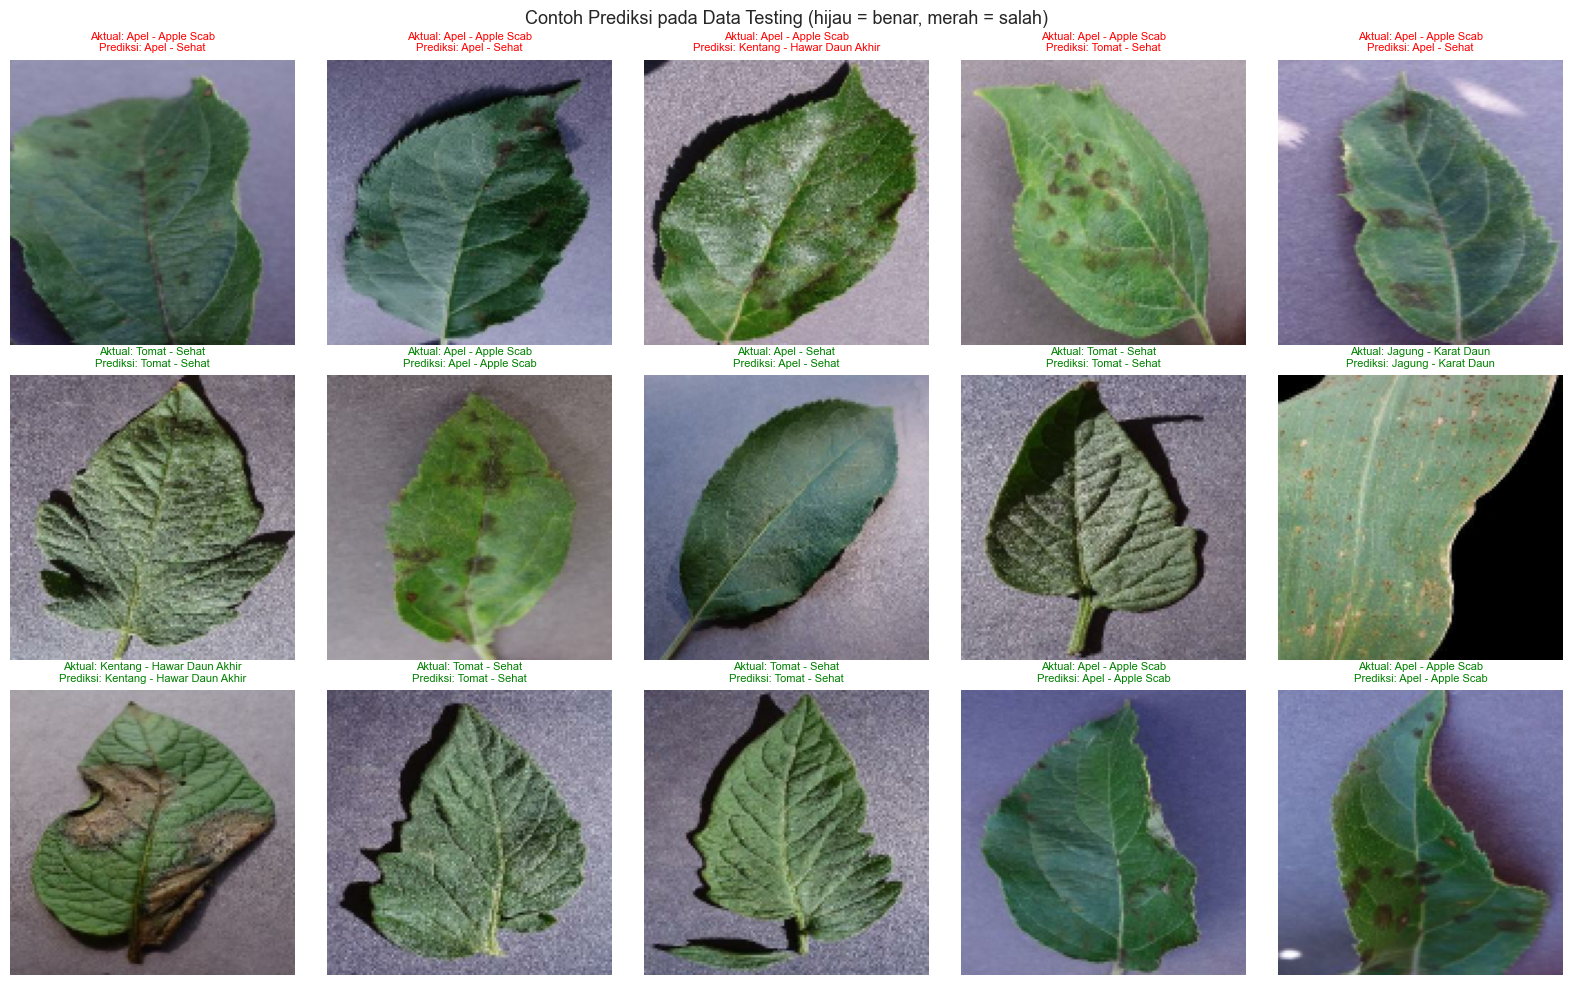

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
idx_salah = np.where(y_pred != y_true)[0]
idx_benar = np.where(y_pred == y_true)[0]
idx_tampil = list(idx_salah[:5]) + list(np.random.choice(idx_benar, min(10, len(idx_benar)), replace=False))

semua_gambar = np.concatenate([x.numpy() for x, _ in test_ds])

for ax, idx in zip(axes.flat, idx_tampil[:15]):
    ax.imshow(semua_gambar[idx].astype("uint8"))
    benar = y_pred[idx] == y_true[idx]
    warna = "green" if benar else "red"
    ax.set_title(f"Aktual: {label_pendek[y_true[idx]]}\nPrediksi: {label_pendek[y_pred[idx]]}",
                 fontsize=8, color=warna)
    ax.axis("off")

plt.suptitle("Prediksi pada Data Testing (hijau = benar, merah = salah)", fontsize=13)
plt.tight_layout()
plt.show()


## 14. Kesimpulan

- Model CNN custom (3 blok Conv2D + MaxPooling, dilatih dari nol tanpa transfer learning) berhasil mengklasifikasikan 5 kelas penyakit/kondisi daun tanaman dari dataset PlantVillage dengan **akurasi testing sekitar 88-89%**.
- Data augmentation (flip, rotasi, zoom, kontras) dipakai buat ngebantu model lebih general mengingat data training per kelas cuma sekitar 244 gambar.
- Callback `EarlyStopping` + `ReduceLROnPlateau` berhasil nyetop training otomatis begitu `val_loss` berhenti membaik, jadi nggak perlu nebak-nebak jumlah epoch yang pas secara manual.
- Dari confusion matrix, kesalahan model kebanyakan terjadi antar kelas yang pola visualnya emang mirip (misalnya Apple Scab vs Apel Sehat, atau kelas-kelas "sehat" yang warnanya cenderung seragam hijau), sementara kelas dengan pola khas kayak Jagung Karat Daun diprediksi sempurna.
- Buat pengembangan lebih lanjut, performa model kemungkinan bisa ditingkatkan lagi dengan transfer learning (misalnya pakai MobileNetV2 dengan bobot ImageNet), menambah jumlah data training per kelas, atau memperdalam arsitektur CNN-nya.